# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

## Ranking results
Measured cpu runtime on the ranking process.

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

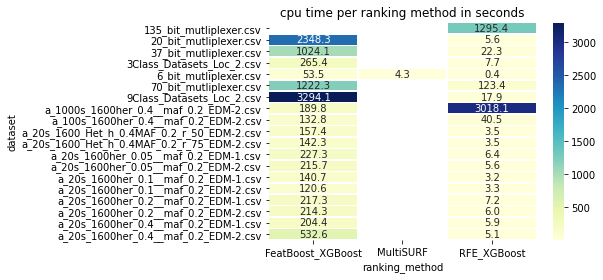

In [19]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from  matplotlib.ticker import FuncFormatter

all_results = pd.DataFrame()
for root, dirs, files, in os.walk("../results/ranking"):
    for file in files:
        dataset_path = os.path.join(root, file)
        results_data = pd.read_csv(dataset_path)
        results_data['dataset'] = file
        all_results = all_results.append(results_data)

rectangular = pd.pivot_table(all_results, values='cpu_time', index=['dataset'], columns=['ranking_method'])
sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu")
plt.title('cpu time per ranking method in seconds')

In [23]:
# sns.catplot(x="dataset_no", y="cpu_time", hue="ranking_method", 
#             data=all_results, col="dataset", col_wrap=4, kind="bar", 
#             facet_kws={'sharey': False})

## Validation results
Validation using KNN.

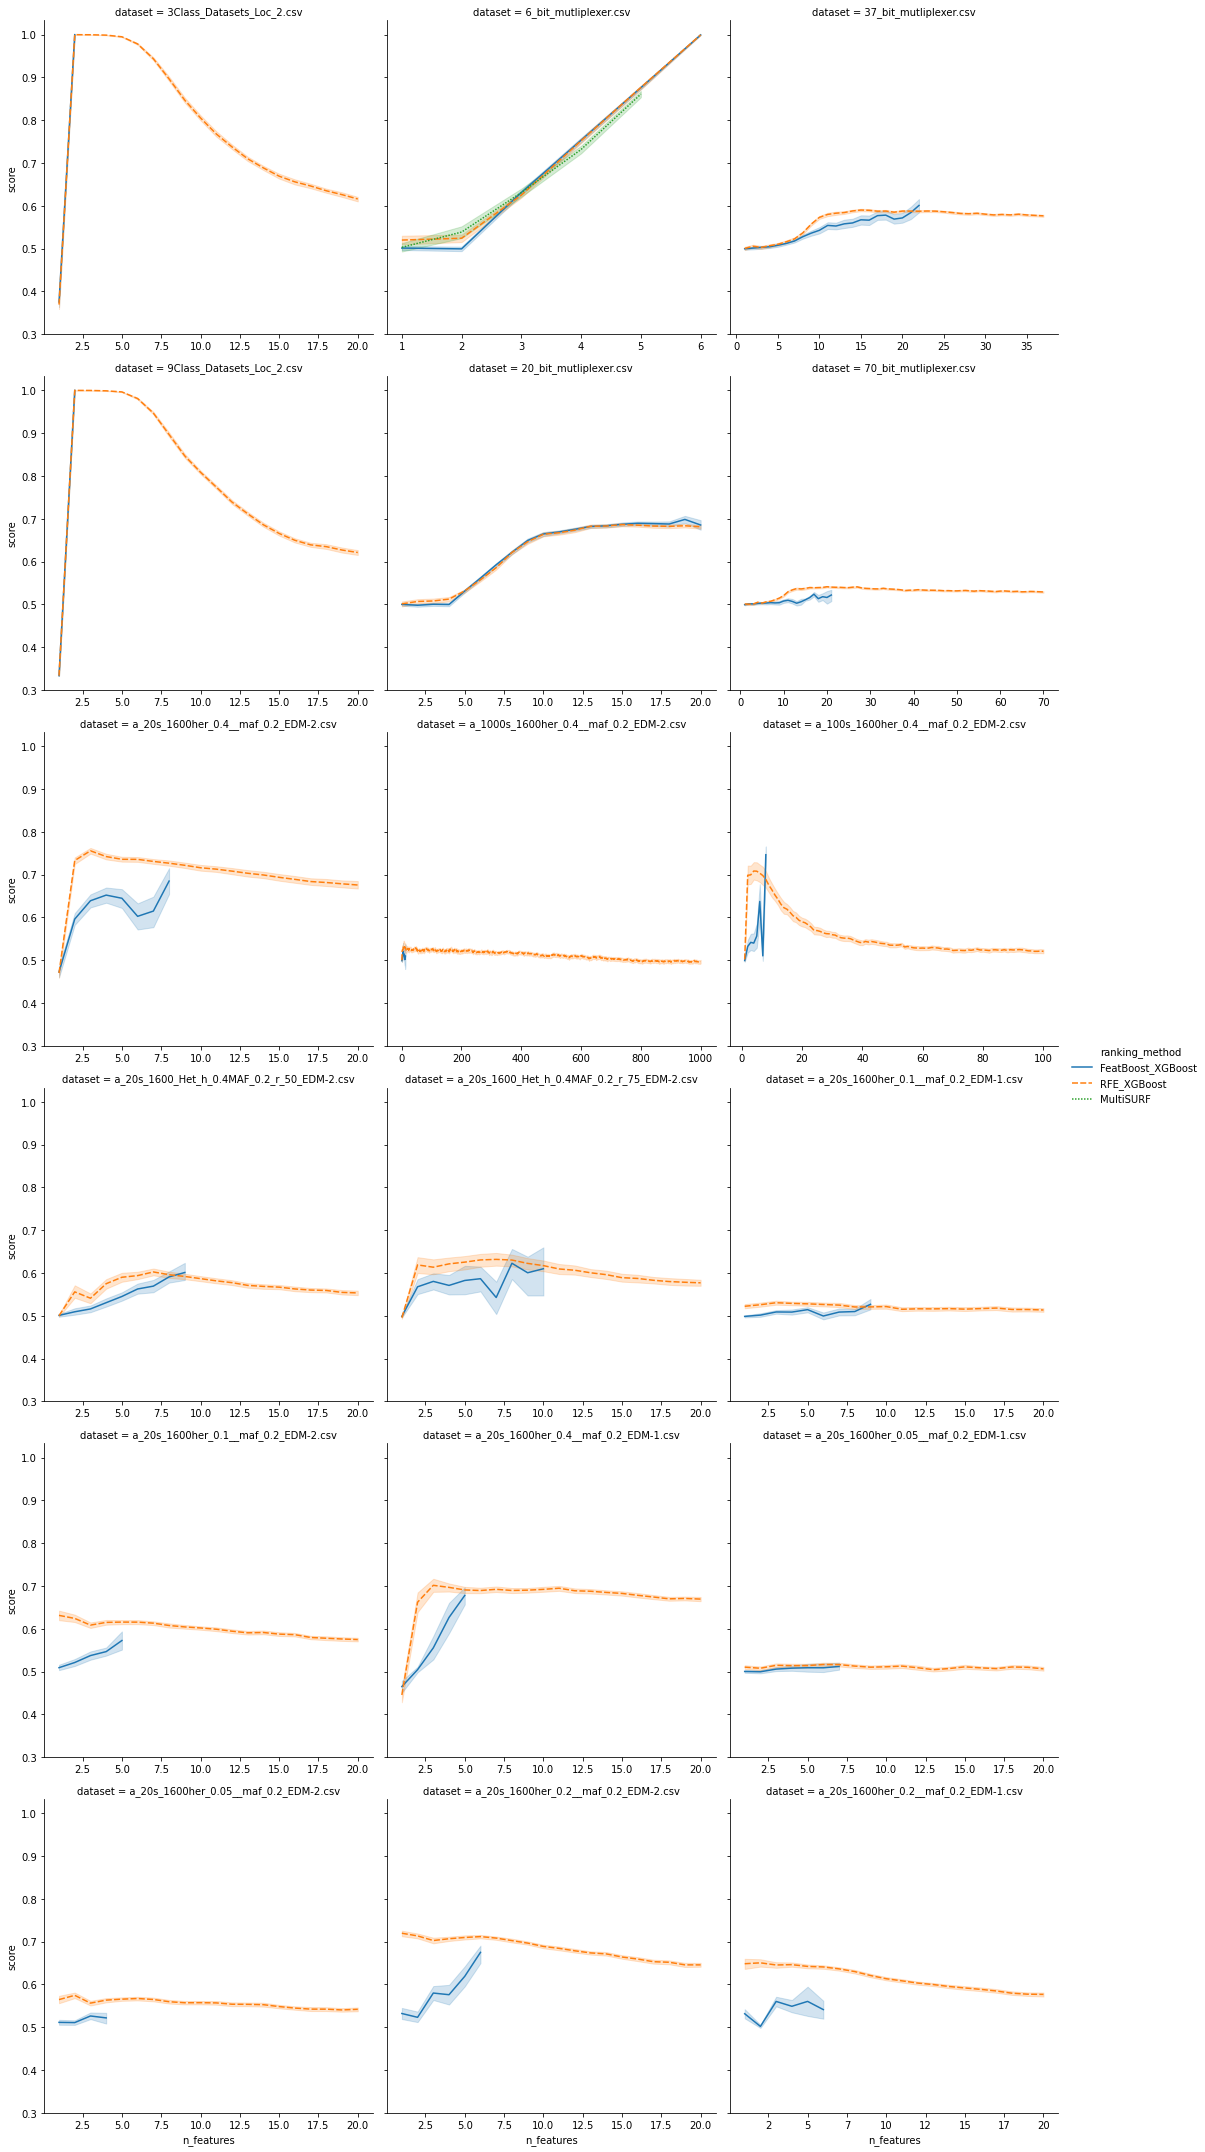

In [22]:
all_results = pd.DataFrame()
for root, dirs, files, in os.walk("../results/validation"):
    for file in files:
        dataset_path = os.path.join(root, file)
        results_data = pd.read_csv(dataset_path)
        results_data['dataset'] = file
        all_results = all_results.append(results_data)

g = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            style="ranking_method", kind="line",
            col_wrap=3,
            facet_kws={'sharex': False},
            data=all_results)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x)))